Feature engineering is the process of using domain knowledge to extract features from raw data. These features can be used to improve the performance of machine learning algorithms.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Feature Engineering/Social_Network_Ads.csv')

In [ ]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
df = df.iloc[:,2:]

In [ ]:
df.sample(5)

,Age,EstimatedSalary,Purchased
210,48,96000,1
272,60,42000,1
52,29,83000,0
293,37,77000,0
208,40,142000,1


Train Test Split

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)
X_train.shape, X_test.shape

((280, 2), (120, 2))

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
# fit the scaler to the train set, it will learn the parameters
scaler.fit(X_train)

# transform train and test sets
X_train_scaled = scaler.transform(X_train) # converted into numpy arrays
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train
# it is a data frame

,Age,EstimatedSalary
92,26,15000
223,60,102000
234,38,112000
232,40,107000
377,42,53000
...,...,...
323,48,30000
192,29,43000
117,36,52000
47,27,54000


X_train and X_test is a data frame but when it is scaled it transforms into numpy array so we again transform it into data frame

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns) # converted into data frame
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

In [ ]:
X_train_scaled # data frame

,Age,EstimatedSalary
0,-1.163172,-1.584970
1,2.170181,0.930987
2,0.013305,1.220177
3,0.209385,1.075582
4,0.405465,-0.486047
...,...,...
275,0.993704,-1.151185
276,-0.869053,-0.775237
277,-0.182774,-0.514966
278,-1.065133,-0.457127


In [ ]:
np.round(X_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [ ]:
np.round(X_train_scaled.describe(), 1) #data is scaled(standardized)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


Effect of Scaling

Text(0.5, 0.98, 'Scaled Data')

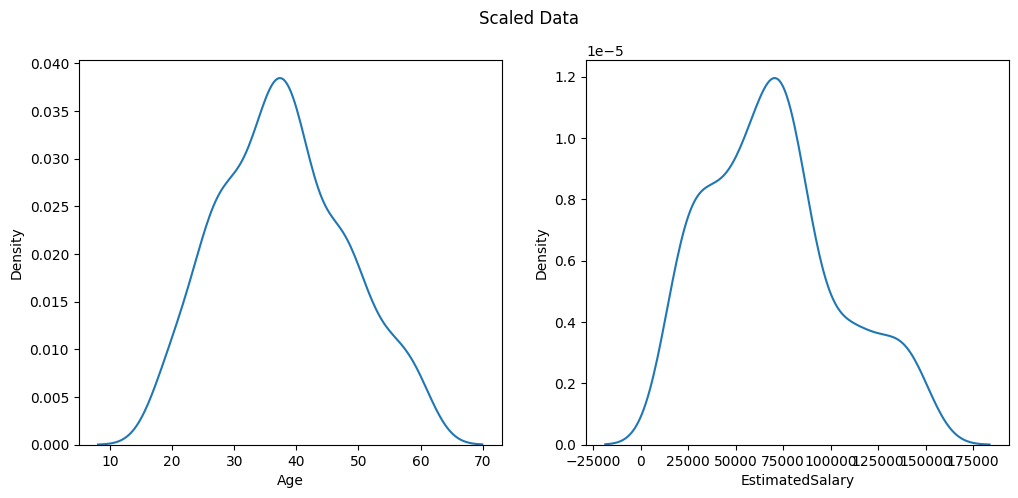

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax2)
fig.suptitle('Scaled Data')


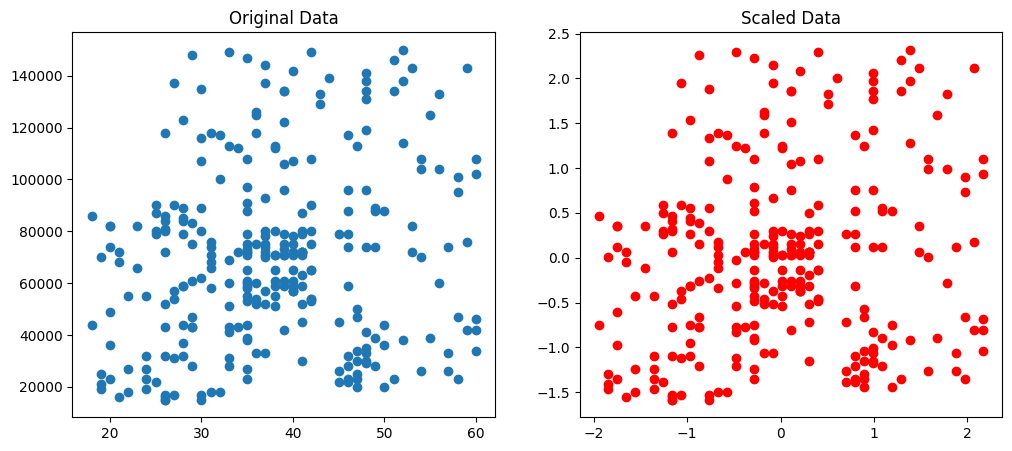

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title('Scaled Data')
ax1.set_title('Original Data')
plt.show()

If you see the above graph the distance betwween the data points is same only mean and sd is changed

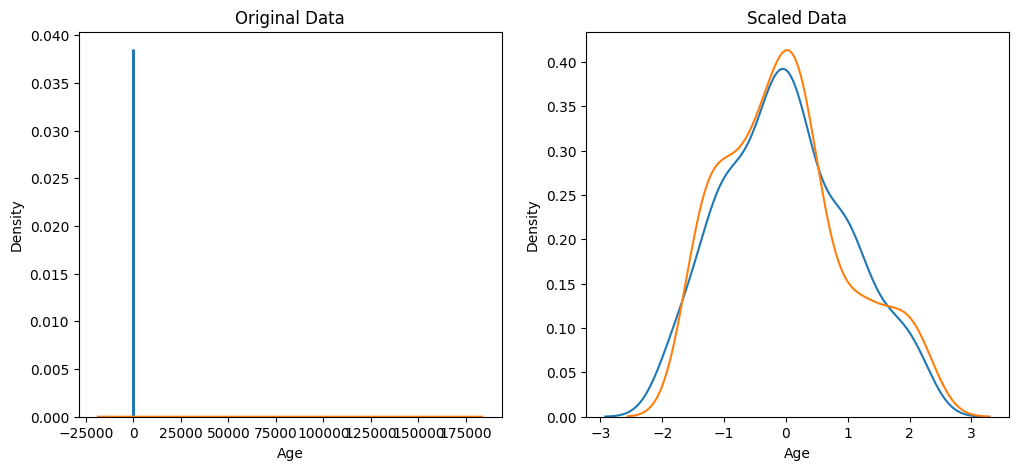

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax1.set_title('before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

# after scaling
ax2.set_title('Scaled Data')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)
plt.show()

Comparison of Distributions

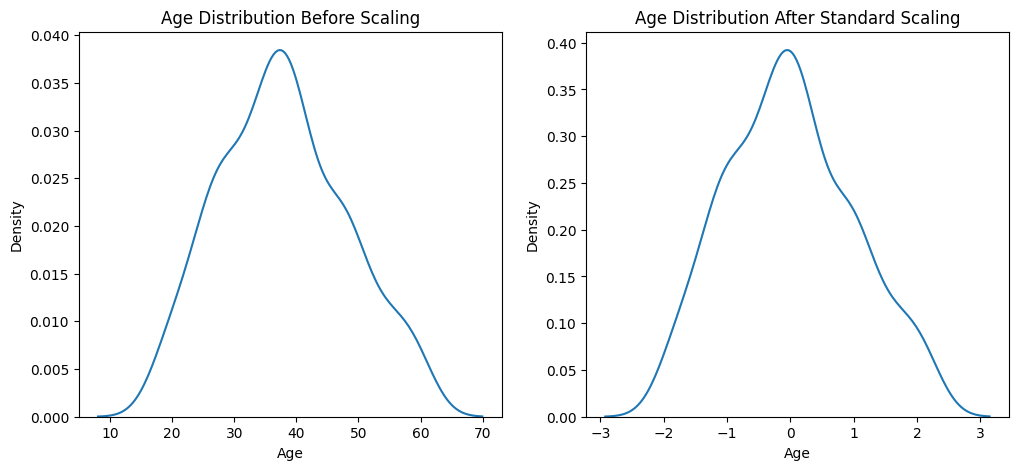

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before Scaling
ax1.set_title('Age Distribution Before Scaling')
sns.kdeplot(X_train['Age'], ax=ax1)

# after Scaling
ax2.set_title('Age Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['Age'], ax=ax2)
plt.show()
# only mean will be changed to 0 and the actual graph will not change

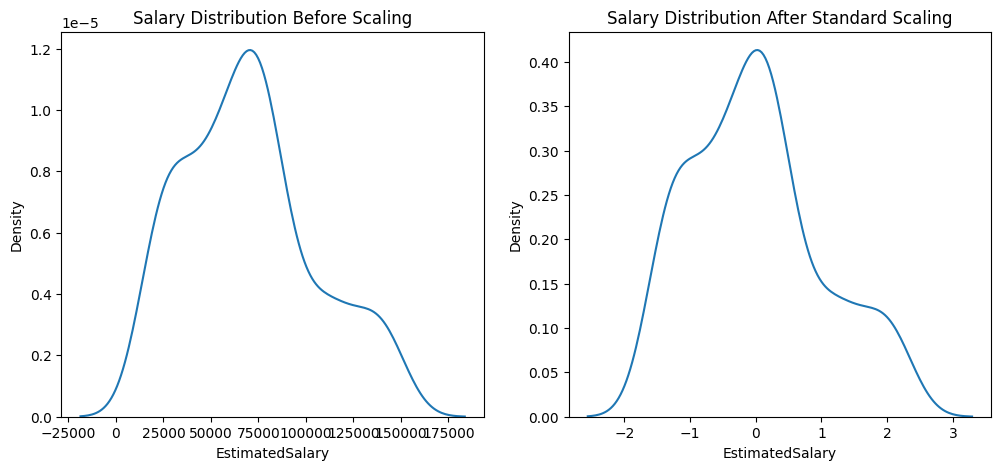

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before Scaling
ax1.set_title('Salary Distribution Before Scaling')
sns.kdeplot(X_train['EstimatedSalary'], ax=ax1)

# after Scaling
ax2.set_title('Salary Distribution After Standard Scaling')
sns.kdeplot(X_train_scaled['EstimatedSalary'], ax=ax2)
plt.show()

Why scaling is important?

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
# two logistic regression is used to compare the effect of scaling
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [ ]:
lr.fit(X_train, y_train) # This LR is trained on original data or unscaled data
lr_scaled.fit(X_train_scaled, y_train) # This LR is trained on Scaled data


LogisticRegression()

In [ ]:
y_pred = lr.predict(X_test)
y_pred_scaled = lr_scaled.predict(X_test_scaled)

In [ ]:
print('Accuracy on unscaled data: ', accuracy_score(y_test, y_pred))
print('Accuracy on scaled data: ', accuracy_score(y_test, y_pred_scaled))

Accuracy on unscaled data:  0.875
Accuracy on scaled data:  0.8666666666666667


Why the Accuracy Difference is Small/Inverted in Your Case:

1. Small Dataset: With only 280 training samples and 120 test samples, the observed difference (0.875 vs. 0.8667) is very minor. It's less than a 1% difference. Such small variations can sometimes be due to random chance, the specific split of the data, or the inherent properties of the dataset.

2. Nature of Logistic Regression's Loss Function: The logistic regression's cost function (log-loss) is convex. While scaling helps optimization converge more efficiently, even without perfect scaling, the optimization algorithm might still find a very similar optimal solution, especially if the data isn't pathologically scaled or extremely sparse. For this particular dataset, the difference in scales might not be severe enough to significantly trap the unscaled model in a poor local minimum.

3. No Explicit Regularization Shown: Your LogisticRegression instantiation doesn't explicitly show C or penalty parameters being changed from their defaults. The default penalty='l2' (L2 regularization) is applied, and while regularization benefits from scaling, the default strength might not be aggressive enough to highlight a massive accuracy difference in this specific scenario.

4. No Significant Skew: As observed, neither Age nor EstimatedSalary seems to have extreme skewness that would disproportionately affect the model's weights without scaling. When features have heavy tails or extreme outliers, scaling becomes more critical.

In [ ]:
# training decision tree - There is no need of scaling in decision tree. See the below example both of the accuracy is same in scaled and unscaled data

In [ ]:
from sklearn.tree import DecisionTreeClassifier

In [ ]:
dt = DecisionTreeClassifier()
dt_scaled = DecisionTreeClassifier()

In [ ]:
dt.fit(X_train, y_train)
dt_scaled.fit(X_train_scaled, y_train)

DecisionTreeClassifier()

In [ ]:
y_pred = dt.predict(X_test)
y_pred_scaled = dt_scaled.predict(X_test_scaled)

In [ ]:
print('Accuracy on unscaled data: ', accuracy_score(y_test, y_pred))
print('Accuracy on scaled data: ', accuracy_score(y_test, y_pred_scaled))

Accuracy on unscaled data:  0.875
Accuracy on scaled data:  0.875


Effect of outliers - Standardization cannot fix the outliers

In [ ]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [ ]:
df = pd.concat([df, pd.DataFrame({'Age': [5,90,95], 'EstimatedSalary':[1000,250000,350000], 'Purchased':[0,1,1]})], ignore_index=True)

In [ ]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1


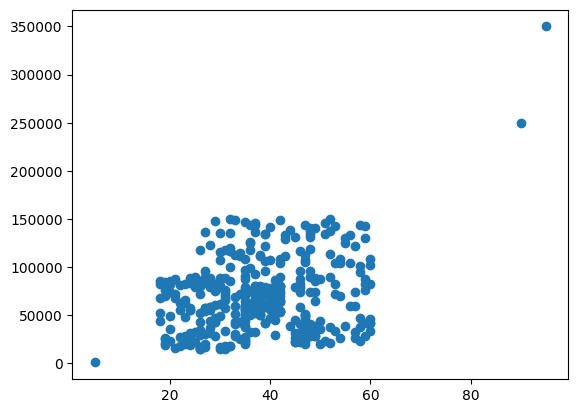

In [ ]:
plt.scatter(df['Age'], df['EstimatedSalary'])
plt.show()
# 3 outliers

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1),
                                                    df['Purchased'],
                                                    test_size=0.3,
                                                    random_state=0)
X_train.shape, X_test.shape

((282, 2), (121, 2))

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns)

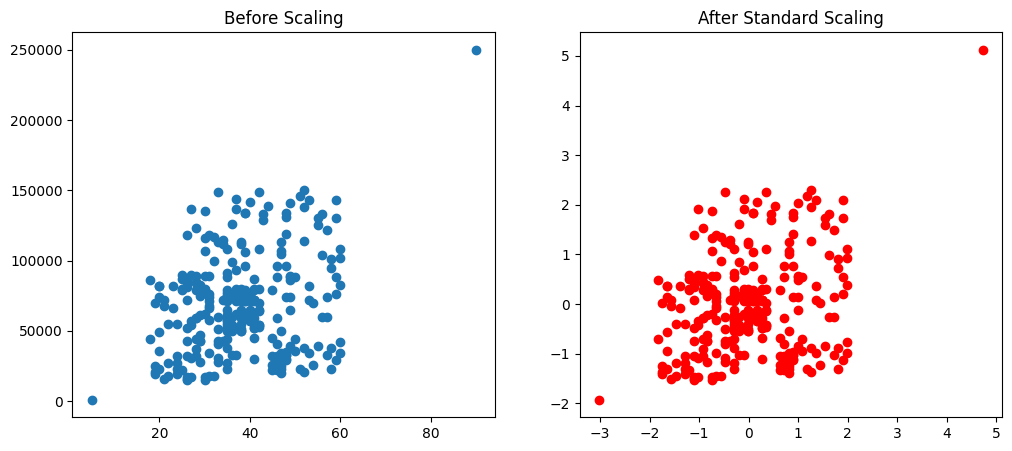

In [ ]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

# before Scaling
ax1.scatter(X_train['Age'], X_train['EstimatedSalary'])
ax1.set_title('Before Scaling')
ax2.scatter(X_train_scaled['Age'], X_train_scaled['EstimatedSalary'], color='red')
ax2.set_title('After Standard Scaling')
plt.show()
# no effect of scaing in outliers. one outlier is missing because it goes on test split

When to use standardization :-
1. K-Means - Use the Euclidean measure
2. KNN - Measure the distance between pairs of samples and these distances are influenced by  the measurement units.
3. PCA - Try to get the feature with maximum variance
4. Artifcial Neural Network - Apply Gradient desent
5. Gradient descent - Theta calculation becomes faster after feature scaling and the learning rate in the apdate equation of Stochastic gradient descent is the same for every parameter.

When not to use Standardization
1. Decision tree
2. XG Boost
3. Random forest